## Prosjekt 2

# Boris Method

By Erik Haddon, Vemund Solli Wilhelmsen, Herman Halvorsen Berggreen

## Todo

Present results. 
Check errors.
Make Banana-plot

Importing necessary libraries.

In [2]:
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.lax as lax
import time

Adding the potential functions.

In [3]:
# Cp = 2d_charged partcle

@jax.jit
def Bcp(x: jnp.array) -> jnp.array:

    """
    Static magnetic field for 2D charged particles

    x: position on form (x1, x2, x3)

    Returns the magnetic field strength
    """

    return jnp.array([0, 0, jnp.sqrt(x[0] ** 2 + x[1] ** 2)])


@jax.jit
def Ucp(x: jnp.array) -> float:
    """
    Electrostatic potential for 2D charged particle
    
    x: position on form (x1, x2, x3)
        
    Returns the potential
    """

    dist = jnp.clip(jnp.sqrt(x[0] ** 2 + x[1] ** 2), 1e-15)

    return 1/ (100 * dist)

@jax.jit
def gradUcp(x :jnp.array) -> jnp.array:
    """
    Gradient of electrostatic potential for 2D charged particle
        
    x: position on form (x1, x2, x3)
            
    Returns the gradient
    """

    dist = jnp.clip(jnp.sqrt(x[0] ** 2 + x[1] ** 2) ** 3, 1e-15)

    return -1/100 * jnp.array([x[0] / dist, x[1]/ dist, 0])


def Energy(x: jnp.array, v: jnp.array, U = Ucp) -> float:

    """
    Energy as sum of kinetic energy and potential energy

    x: position on form (x1, x2, x3)
    v: velocity on form (v1, v2, v3)

    Returns energy as scalar
    """

    return 1/2 * jnp.linalg.norm(v, ord = 2, axis = 0) ** 2 + U(x)

In [4]:
# Using solve_ivp to calculate the v(-0.05h)
def system(t: jnp.array, Y: jnp.array, h: float = 0.1, B= Bcp, gradU = gradUcp):
    x = Y[:3]
    v = Y[3:]
    dxdt = v
    dvdt = jnp.cross(v, B(x)) - gradU(x)
    return jnp.concatenate((dxdt, dvdt))

In [5]:
def initial_velocity(x0: jnp.array, v0: jnp.array, h: float = 0.1, B= Bcp, U = Ucp, gradU = gradUcp) -> jnp.array:
    """
    Calculates the initial velocity v(t_0 - h/2).
    The Boris method uses positions and velocity at timeintervals h/2  apart.

    x0: x(t_0) array with shape 3.
    v0: v(t_0) arrau of shape 3.
    
    Returns v(t_0 -h/2)
    """
    # Using solve_ivp to calculate the v(-0.05h)
    def system(t: jnp.array, Y: jnp.array, h: float = 0.1):
        x = Y[:3]
        v = Y[3:]
        dxdt = v
        dvdt = jnp.cross(v, B(x)) - gradU(x)
        return jnp.concatenate((dxdt, dvdt))

    Y0 = jnp.concatenate((x0, v0))    # Everything in solvebvp must be one in one vector.

    sol = solve_ivp(system, (0, -h/2), Y0)
    v_initial = sol.y[3:, -1]

    return v_initial

In [6]:
def Boris_method(x0: jnp.array, v0: jnp.array, B, U, gradU, T: int = 10**4, h: float = 0.1) -> tuple[jnp.array, jnp.array]:

    """
    Boris_method, calculates the position and velocity of the particle at time t.

    x0: Iinitial position, array of size 3.
    v0: Iinitial velocity, array of size 3.
    T:  Total time.
    h:  Steplength in time.

    return: arrays of positions and velocities.
    """

    N = int(T/h)

    v_init = initial_velocity(x0, v0, h)
    x = x0
    v = v_init

    @jax.jit
    def Boris_step(x: jnp.array, v: jnp.array, h: jnp.array = 0.1) -> tuple[jnp.array, jnp.array]:
        """
        Calculates one step of the Boris method


        x: Current position, array of size 3.
        v: Current velocity, array of size 3.
        h:  Steplength in time.
        
        return: x_next, v_nect
        """

        v_minus = v -  h/2 * gradU(x)    #v_minus

        t = h/2 * B(x)
        s = 2 * t / (1 + t @ t)
        v_prime = v_minus + jnp.cross(v_minus, t)
        v_plus = v_minus + jnp.cross(v_prime, s) 

        v_next = v_plus - h/2 * gradU(x)
        x_next = x + h * v_next

        return x_next, v_next




    def body(carry, _):
        x, v  = carry
        x, v = Boris_step(x, v)

        return (x, v), (x,v)

    (_, _), trajectory = lax.scan(body, (x, v), xs = None, length = N)

    positions, velocities = trajectory

    positions = jnp.concatenate([x0[None, :], positions], axis=0)

    velocities = jnp.concatenate([v_init[None, :], velocities], axis=0)
    v_averages = 1/2 * (velocities[:-1] + velocities[1:])
    return positions[:-1], v_averages


In [7]:
def plot_trajectory(positions):

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(positions[:,0], positions[:, 1], label = "Position")
    ax.set_ylabel("Position y")
    ax.set_xlabel("Position x")
    ax.grid(True)
    ax.legend()
    ax.set_title("Position of a electrically charged particle")
    plt.show()
    return

positions= [0.  1.  0.1] velocities = [0.08990236 0.04993388 0.2       ]


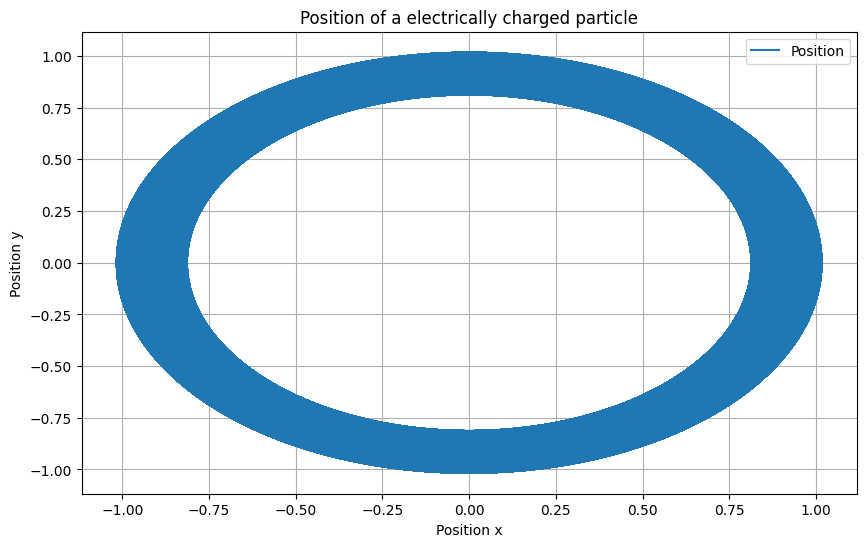

In [8]:
# Initial conditions
x0 = jnp.array([0, 1, 0.1])
v0 = jnp.array([0.09, 0.05, 0.20])

h = 0.1    # Steplength in time
t_0 = 0
T = 10**5  # Total time
t = jnp.arange(t_0, T, h)


positions, velocities = Boris_method(x0, v0, Bcp, Ucp, gradUcp, T, h)
# print(f"Shape of positions = {positions.shape}, shape of velocities: {velocities.shape}")
print(f"positions= {positions[0]} velocities = {velocities[0]}")

plot_trajectory(positions)

Solving initial value problem to estimate the error.


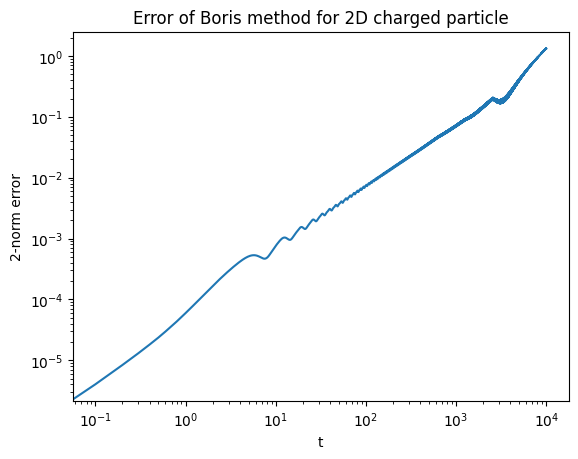

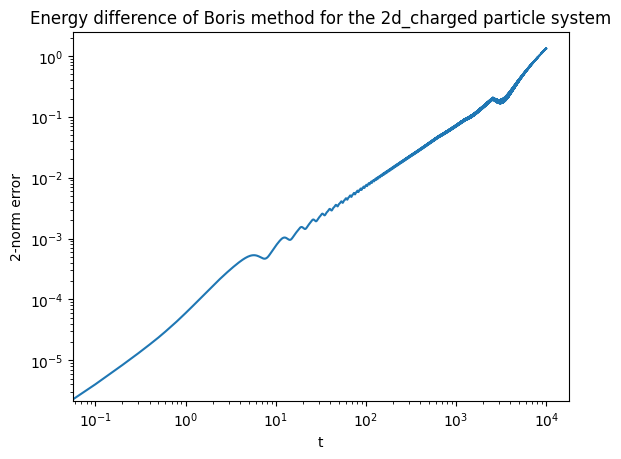

In [9]:
h = 0.1    # Steplength in time
t_0 = 0
T = 10**4  # Total time
t = jnp.arange(t_0, T, h)

positions, velocities = Boris_method(x0, v0, Bcp, Ucp, gradUcp, T, h)


print("Solving initial value problem to estimate the error.")
# Creating a reference solution to estimate error
y_0 = jnp.concatenate((x0, v0), axis = None)


def Use_ivp(t, Y, h: float = 0.1, B= Bcp, U = Ucp, gradU = gradUcp):
    def system(t: jnp.array, Y: jnp.array, h: float = 0.1, B= Bcp, U = Ucp, gradU = gradUcp):
        x = Y[:3]
        v = Y[3:]
        dxdt = v
        dvdt = jnp.cross(v, B(x)) - gradU(x)
        return jnp.concatenate((dxdt, dvdt))
    
    # Lowered the tolerances from what was speciefied in the task, as this took a long time
    sol = solve_ivp(system, (t_0, T), y_0, t_eval=t, method = "RK45", rtol=1e-8, atol=1e-10)
    return sol

ref_sol = Use_ivp(t, y_0)
x_ref = ref_sol.y[:3]
v_ref = ref_sol.y[3:]

x_ref = ref_sol.y[:3].T

Boris_error = jnp.linalg.norm(positions - x_ref, ord = 2, axis = 1)

plt.plot(t, Boris_error)
plt.semilogy()
plt.xscale("log")
plt.xlabel("t")
plt.ylabel(r"2-norm error")
plt.title("Error of Boris method for 2D charged particle")
plt.show()

energy_diff_Boris = abs(Energy(positions, velocities) - Energy(x0, v0))
plt.plot(t, Boris_error)
plt.semilogy()
plt.xscale("log")
plt.xlabel("t")
plt.ylabel(r"2-norm error")
plt.title("Energy difference of Boris method for the 2d_charged particle system")
plt.show()


With h = 0.1 and T = 100.0 the Boris method uses 0.0411s
With h = 0.05 and T = 100.0 the Boris method uses 0.0414s
With h = 0.025 and T = 100.0 the Boris method uses 0.0426s
[Array(0.02493628, dtype=float32), Array(20.001524, dtype=float32), Array(60.00191, dtype=float32)]


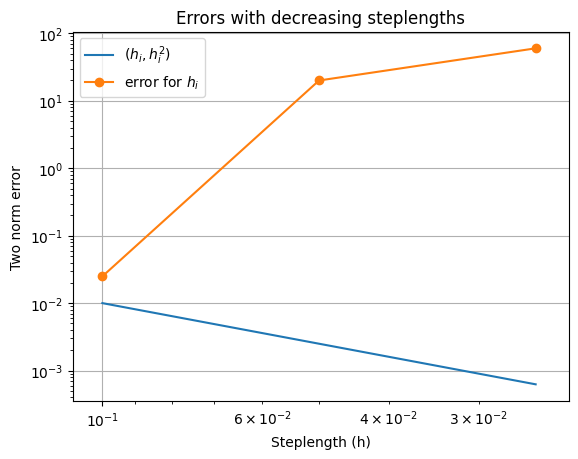

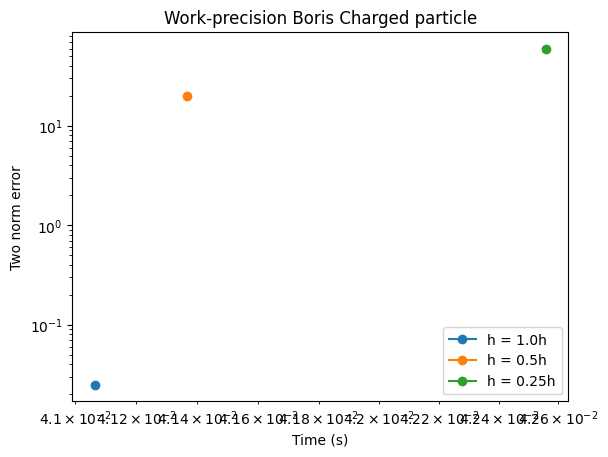

In [27]:
# Initial conditions
x0 = jnp.array([0, 1, 0.1])
v0 = jnp.array([0.09, 0.05, 0.20])

T = 1E2
t_0 = 0
h = 0.1 
N = 3       # number of steplengths 


global_errors = [] 
h_list = []
h2_list = []
# h4_list = []
times = []
for i in range(N):

    h_list.append(h)
    h2_list.append(h**2)
    # h4_list.append(h**4)
    
    # Creating a reference solution to estimate error
    y_0 = jnp.concatenate((x0, v0), axis = None)
    t= jnp.linspace(0, T, int(T/h))

    ref_sol = Use_ivp(t, y_0, h, Bcp, Ucp, gradUcp)

    x_ref = ref_sol.y[:3]
    v_ref = ref_sol.y[3:]
    x_ref = ref_sol.y[:3].T

    start = time.perf_counter()
    positions, velocities = Boris_method(x0, v0, Bcp, Ucp, gradUcp, T, h)
    stop = time.perf_counter()
    print(f"With h = {h} and T = {T} the Boris method uses {round(stop - start, 4)}s")
    times.append(stop-start)

    global_errors.append(jnp.linalg.norm(positions[-1] - x_ref[-1], ord = 2))


    h /= 2

print(global_errors)

plt.plot(h_list, h2_list, label = r"$(h_i, h_i^2)$")
plt.plot(h_list, global_errors, label = r"error for $h_i$", marker = "o")
plt.loglog()
plt.xlabel("Steplength (h)")
plt.xlim(h_list[0] + 0.1 * h_list[0], h_list[-1] - 0.1 * h_list[-1])
plt.ylabel("Two norm error")
plt.title("Errors with decreasing steplengths")
plt.legend()
plt.grid(True)
plt.show()

for i in range(N):
    plt.plot(times[i], global_errors[i], marker = "o", label = f"h = {h_list[i]/0.1}h")

plt.loglog()
plt.xlabel("Time (s)")
plt.ylabel("Two norm error")
plt.title("Work-precision Boris Charged particle")
plt.legend()
plt.show()





In [11]:
def Btok(x: jnp.array) -> jnp.array:

    """
    Static magnetic field for Tokamak system

    x: position on form (x1, x2, x3)

    Returns the magnetic field strength
    """
    
    r = jnp.clip(jnp.sqrt(x[0] ** 2 + x[1] ** 2), 1e-15)

    return jnp.array([-(2 * x[1] + x[0]*x[2]) / (2 * r**2),
                          (2*x[0] - x[1]*x[2]) / (2* r**2),
                                    (r - 1) / (2 * r)])


@jax.jit
def Utok(x: jnp.array) -> float:
    """
    Electrostatic potential for Tokamak system
    
    x: position on form (x1, x2, x3)
        
    Returns the potential
    """

    return 0

@jax.jit
def gradUtok(x :jnp.array) -> jnp.array:
    """
    Gradient of electrostatic potential for the Tokamak
        
    x: position on form (x1, x2, x3)
            
    Returns the gradient
    """
    return 0


def Energy2(x: jnp.array, v: jnp.array, U = Utok) -> float:

    """
    Energy as sum of kinetic energy and potential energy

    x: position on form (x1, x2, x3)
    v: velocity on form (v1, v2, v3)

    Returns energy as scalar
    """

    return 1/2 * jnp.linalg.norm(v, ord = 2, axis = 0) ** 2 + U(x)

[1.2 0.  0. ]
[-0.00028764  0.00047152 -0.00207098]


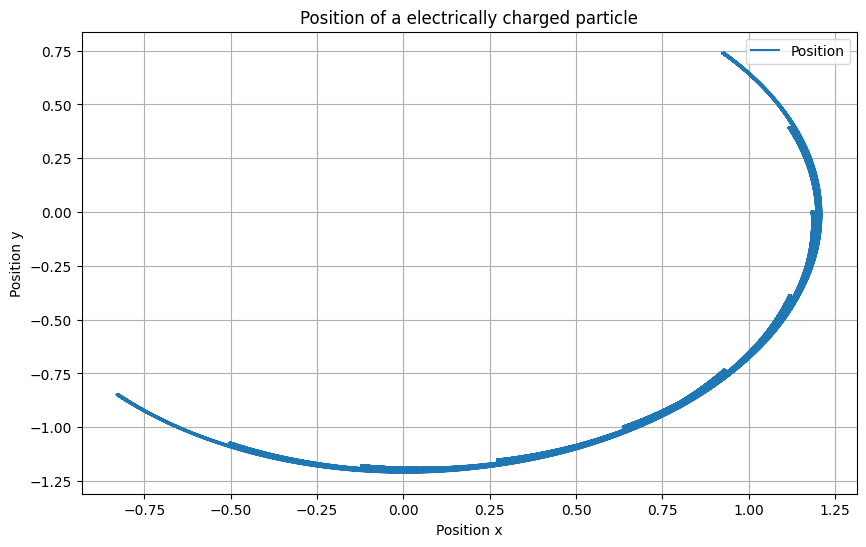

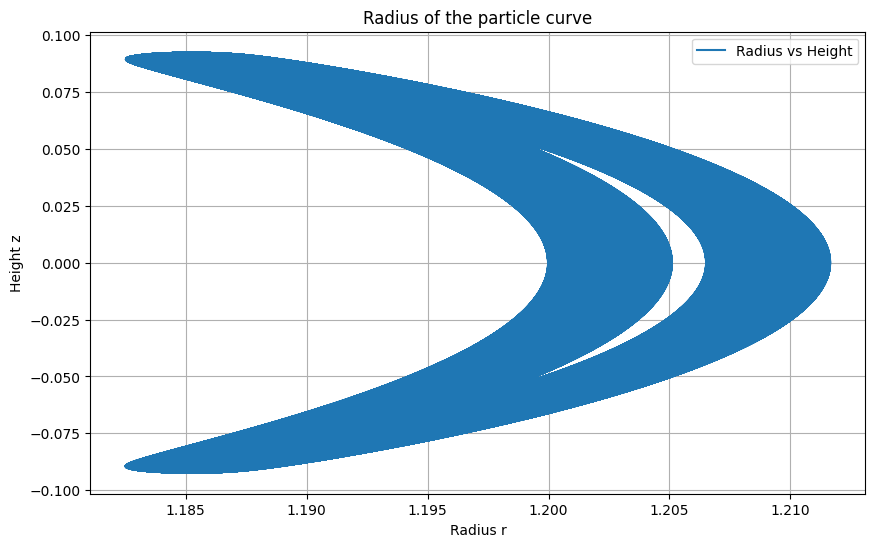

In [12]:
# Initial conditions
x0 = jnp.array([1.2, 0, 0])
v0 = jnp.array([0, 4.816* 10**(-4),  -2.059*10**(-3)])

h = 0.1    # Steplength
t_0 = 0
T = 10**5  # Total time 
t = jnp.arange(t_0, T, h)


positions, velocities = Boris_method(x0, v0, Btok, Utok, gradUtok, T, h)

print(positions[0])
print(velocities[0])

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(positions[:,0], positions[:, 1], label = "Position")
ax.set_ylabel("Position y")
ax.set_xlabel("Position x")
ax.grid(True)
ax.legend()
ax.set_title("Position of a electrically charged particle")
plt.show()


radius = jnp.sqrt(positions[:,0]**2 + positions[:,1]**2)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(radius, positions[:,2], label = "Radius vs Height")
ax.set_ylabel("Height z")
ax.set_xlabel("Radius r")
ax.grid(True)
ax.legend()
ax.set_title("Position of a charged particle in the Tokamak system")
plt.title("Radius of the particle curve")
plt.show()

Solving initial value problem to estimate the error.


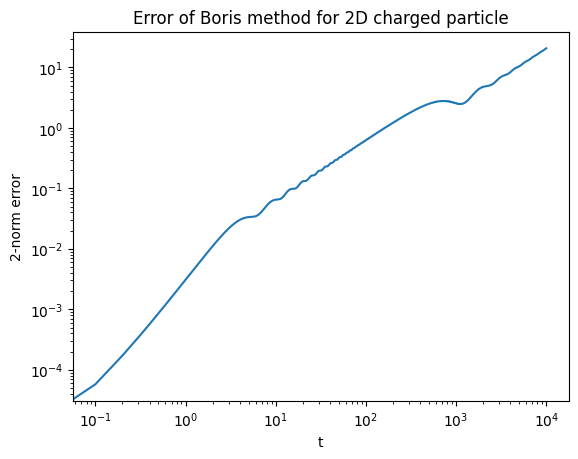

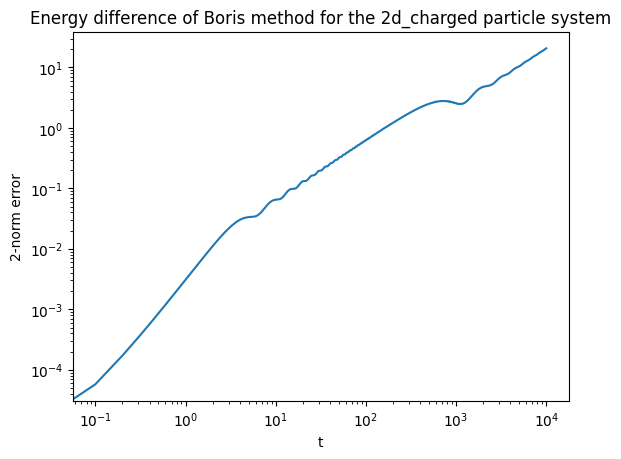

In [13]:
# Initial conditions
x0 = jnp.array([1.2, 0, 0])
v0 = jnp.array([0, 4.816* 10**(-4),  -2.059*10**(-3)])

h = 0.1    # Steplength in time
t_0 = 0
T = 10**4  # Total time
t = jnp.arange(t_0, T, h)

positions, velocities = Boris_method(x0, v0, Btok, Utok, gradUtok, T, h)


print("Solving initial value problem to estimate the error.")
# Creating a reference solution to estimate error
y_0 = jnp.concatenate((x0, v0), axis = None)

ref_sol = Use_ivp(t, y_0, h, Btok, Utok, gradUtok)
x_ref = ref_sol.y[:3]
v_ref = ref_sol.y[3:]

x_ref = ref_sol.y[:3].T

Boris_error = jnp.linalg.norm(positions - x_ref, ord = 2, axis = 1)

plt.plot(t, Boris_error)
plt.semilogy()
plt.xscale("log")
plt.xlabel("t")
plt.ylabel(r"2-norm error")
plt.title("Error of Boris method for 2D charged particle")
plt.show()

energy_diff_Boris = abs(Energy(positions, velocities) - Energy(x0, v0))
plt.plot(t, Boris_error)
plt.semilogy()
plt.xscale("log")
plt.xlabel("t")
plt.ylabel(r"2-norm error")
plt.title("Energy difference of Boris method for the 2d_charged particle system")
plt.show()


With h = 0.1 and T = 100.0 the Boris method uses 0.0467s
With h = 0.05 and T = 100.0 the Boris method uses 0.0411s
With h = 0.025 and T = 100.0 the Boris method uses 0.0417s
With h = 0.0125 and T = 100.0 the Boris method uses 0.0422s
With h = 0.00625 and T = 100.0 the Boris method uses 0.0642s
With h = 0.003125 and T = 100.0 the Boris method uses 0.0444s
With h = 0.0015625 and T = 100.0 the Boris method uses 0.0466s
[Array(0.6216478, dtype=float32), Array(0.6491861, dtype=float32), Array(0.69874144, dtype=float32), Array(0.79959273, dtype=float32), Array(0.98314583, dtype=float32), Array(1.2574995, dtype=float32), Array(1.2882762, dtype=float32)]


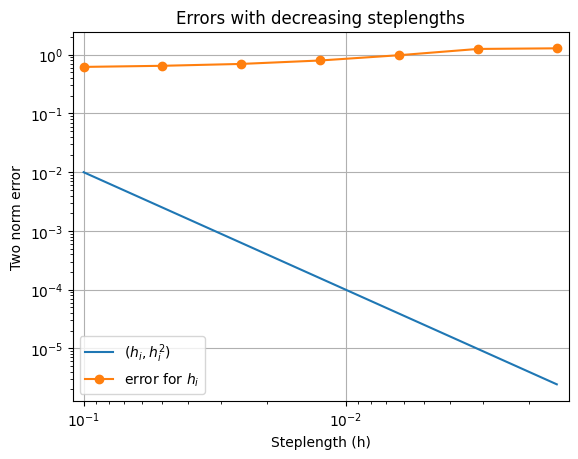

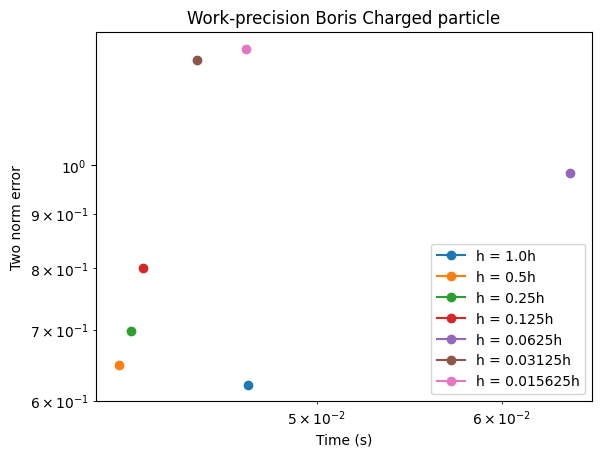

In [14]:
# Initial conditions
x0 = jnp.array([1.2, 0, 0])
v0 = jnp.array([0, 4.816* 10**(-4),  -2.059*10**(-3)])


T = 1E2
t_0 = 0
h = 0.1 
N = 7       # number of steplengths 


global_errors = [] 
h_list = []
h2_list = []
# h4_list = []
times = []
for i in range(N):

    h_list.append(h)
    h2_list.append(h**2)
    # h4_list.append(h**4)
    
    # Creating a reference solution to estimate error
    y_0 = jnp.concatenate((x0, v0), axis = None)
    t= jnp.linspace(0, T, int(T/h))

    ref_sol = Use_ivp(t, y_0, h, Btok, Utok, gradUtok)

    x_ref = ref_sol.y[:3]
    v_ref = ref_sol.y[3:]
    x_ref = ref_sol.y[:3].T

    start = time.perf_counter()
    positions, velocities = Boris_method(x0, v0, Btok, Utok, gradUtok, T, h)
    stop = time.perf_counter()
    print(f"With h = {h} and T = {T} the Boris method uses {round(stop - start, 4)}s")
    times.append(stop-start)

    global_errors.append(jnp.linalg.norm(positions[-1] - x_ref[-1], ord = 2))


    h /= 2

print(global_errors)

plt.plot(h_list, h2_list, label = r"$(h_i, h_i^2)$")
plt.plot(h_list, global_errors, label = r"error for $h_i$", marker = "o")
plt.loglog()
plt.xlabel("Steplength (h)")
plt.xlim(h_list[0] + 0.1 * h_list[0], h_list[-1] - 0.1 * h_list[-1])
plt.ylabel("Two norm error")
plt.title("Errors with decreasing steplengths")
plt.legend()
plt.grid(True)
plt.show()

for i in range(N):
    plt.plot(times[i], global_errors[i],  marker = "o", label = f"h = {h_list[i]/0.1}h")

plt.loglog()
plt.xlabel("Time (s)")
plt.ylabel("Two norm error")
plt.title("Work-precision Boris Charged particle")
plt.legend()
plt.show()
